```markdown
# Delivery Time Prediction Project: End-to-End ML Pipeline Documentation

This notebook documents the building of an end-to-end Machine Learning pipeline to predict the delivery time (in minutes) for orders based on various factors.

---

## 1. Project Workflow Overview
1. **Data Loading & Inspection**: Imported the dataset, examined the target variable `Time_taken (min)`, and identified missing values and feature formats.
2. **Data Cleaning & Handling Nulls**:
   * Imputed delivery agent age and rating nulls using mean and median values.
   * Dropped geographical coordinates containing anomaly values of `0.0` degrees.
   * Filled categorical features like `Weather_conditions` and `Road_traffic_density` with their corresponding statistical modes.
3. **Exploratory Data Analysis (EDA)**:
   * Visualized target distributions and correlations between numeric columns.
   * Analyzed key factors like weather, traffic density, and age groups on overall delivery speed.
4. **Feature Engineering**:
   * Calculated exact geodesic travel distances using the **Haversine formula** from restaurant coordinates to customer coordinates.
   * Parsed delivery hours from order timestamps to capture temporal patterns.
5. **Encoding & Scaling**:
   * Encoded ordinal features like `Road_traffic_density` and one-hot encoded nominal values.
   * Normalized training features using a standard scaling method.
6. **Model Selection & Evaluation**:
   * Trained and evaluated baseline linear, decision tree, random forest, and XGBoost models.
   * Performed Hyperparameter optimization using Randomized Search CV.
   * Decided on the **Tuned Random Forest Regressor** as the champion production model due to its high test-set R² score (~0.827) and stable generalizability.

---

## 2. Model Performance Summary

| Model | Dataset | Mean Absolute Error (MAE) | Root Mean Squared Error (RMSE) | R² Score |
| :--- | :--- | :--- | :--- | :--- |
| **Linear Regression** | Test | 4.793 | 6.014 | 0.585 |
| **Decision Tree** | Test | 4.151 | 5.489 | 0.654 |
| **XGBoost (Tuned)** | Test | 3.102 | 3.903 | 0.825 |
| **Random Forest (Tuned)** | **Test** | **3.088** | **3.882** | **0.827** |

*The Tuned Random Forest model was successfully serialized into `rf_best.pkl` alongside the standard scaler for production use.*
```

In [417]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [418]:
df = pd.read_csv("data.csv")

In [419]:
df.shape

(45584, 20)

In [420]:
df.columns

Index(['ID', 'Delivery_person_ID', 'Delivery_person_Age',
       'Delivery_person_Ratings', 'Restaurant_latitude',
       'Restaurant_longitude', 'Delivery_location_latitude',
       'Delivery_location_longitude', 'Order_Date', 'Time_Orderd',
       'Time_Order_picked', 'Weather_conditions', 'Road_traffic_density',
       'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle',
       'multiple_deliveries', 'Festival', 'City', 'Time_taken (min)'],
      dtype='object')

In [421]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45584 entries, 0 to 45583
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45584 non-null  object 
 1   Delivery_person_ID           45584 non-null  object 
 2   Delivery_person_Age          43730 non-null  float64
 3   Delivery_person_Ratings      43676 non-null  float64
 4   Restaurant_latitude          45584 non-null  float64
 5   Restaurant_longitude         45584 non-null  float64
 6   Delivery_location_latitude   45584 non-null  float64
 7   Delivery_location_longitude  45584 non-null  float64
 8   Order_Date                   45584 non-null  object 
 9   Time_Orderd                  43853 non-null  object 
 10  Time_Order_picked            45584 non-null  object 
 11  Weather_conditions           44968 non-null  object 
 12  Road_traffic_density         44983 non-null  object 
 13  Vehicle_conditio

In [422]:
df.head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min)
0,0xcdcd,DEHRES17DEL01,36.0,4.2,30.327968,78.046106,30.397968,78.116106,12-02-2022,21:55,22:10,Fog,Jam,2,Snack,motorcycle,3.0,No,Metropolitian,46
1,0xd987,KOCRES16DEL01,21.0,4.7,10.003064,76.307589,10.043064,76.347589,13-02-2022,14:55,15:05,Stormy,High,1,Meal,motorcycle,1.0,No,Metropolitian,23
2,0x2784,PUNERES13DEL03,23.0,4.7,18.562450,73.916619,18.652450,74.006619,04-03-2022,17:30,17:40,Sandstorms,Medium,1,Drinks,scooter,1.0,No,Metropolitian,21
3,0xc8b6,LUDHRES15DEL02,34.0,4.3,30.899584,75.809346,30.919584,75.829346,13-02-2022,09:20,09:30,Sandstorms,Low,0,Buffet,motorcycle,0.0,No,Metropolitian,20
4,0xdb64,KNPRES14DEL02,24.0,4.7,26.463504,80.372929,26.593504,80.502929,14-02-2022,19:50,20:05,Fog,Jam,1,Snack,scooter,1.0,No,Metropolitian,41


In [423]:
df.isnull().mean()*100

,0
ID,0.000000
Delivery_person_ID,0.000000
Delivery_person_Age,4.067217
Delivery_person_Ratings,4.185679
Restaurant_latitude,0.000000
Restaurant_longitude,0.000000
Delivery_location_latitude,0.000000
Delivery_location_longitude,0.000000
Order_Date,0.000000
Time_Orderd,3.797385


In [424]:
df = df.drop(columns=["ID","Delivery_person_ID"])

In [425]:
df.columns


Index(['Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude',
       'Restaurant_longitude', 'Delivery_location_latitude',
       'Delivery_location_longitude', 'Order_Date', 'Time_Orderd',
       'Time_Order_picked', 'Weather_conditions', 'Road_traffic_density',
       'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle',
       'multiple_deliveries', 'Festival', 'City', 'Time_taken (min)'],
      dtype='object')

In [426]:
df[df["Delivery_person_Age"]>40]

,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min)
3577,50.0,6.0,-12.970324,-77.645748,13.010324,77.685748,13-03-2022,NaN,12:30,NaN,NaN,3,Meal,electric_scooter,0.0,No,Urban,25
4705,50.0,6.0,-17.451976,-78.385883,17.561976,78.495883,04-04-2022,NaN,23:20,NaN,NaN,3,Snack,bicycle,0.0,No,Metropolitian,27
5160,50.0,6.0,-26.910262,-75.783013,27.020262,75.893013,18-03-2022,NaN,18:50,NaN,NaN,3,Drinks,scooter,1.0,No,Metropolitian,20
5353,50.0,6.0,12.914264,77.678400,13.024264,77.788400,06-04-2022,NaN,20:55,NaN,NaN,3,Meal,electric_scooter,1.0,No,Metropolitian,18
5642,50.0,6.0,-27.159795,-78.042990,27.209795,78.092990,13-02-2022,NaN,18:05,NaN,NaN,3,Drinks,scooter,1.0,No,Metropolitian,20
6385,50.0,6.0,26.911927,75.797282,27.041927,75.927282,02-04-2022,NaN,22:10,NaN,NaN,3,Meal,electric_scooter,0.0,No,Urban,20
7022,50.0,6.0,-12.352058,-76.606650,12.372058,76.626650,15-03-2022,NaN,0.416666667,NaN,NaN,3,Buffet,scooter,1.0,No,Metropolitian,14
7672,50.0,6.0,0.000000,0.000000,0.010000,0.010000,21-03-2022,NaN,08:35,NaN,NaN,3,Meal,bicycle,1.0,No,Metropolitian,22
9490,50.0,6.0,12.933298,77.614293,13.003298,77.684293,12-03-2022,NaN,18:25,NaN,NaN,3,Drinks,scooter,1.0,No,Urban,17
9526,50.0,6.0,-23.374989,-85.335486,23.444989,85.405486,20-03-2022,NaN,17:55,NaN,NaN,3,Snack,bicycle,1.0,No,Metropolitian,32


In [427]:
df["Delivery_person_Age"].value_counts()

,count
Delivery_person_Age,
35.0,2261
36.0,2260
37.0,2226
30.0,2226
38.0,2218
24.0,2210
32.0,2201
22.0,2194
29.0,2191


In [428]:
df["Delivery_person_Age"].isnull().mean()*100

np.float64(4.067216567216567)

(array([  38., 4289., 8664., 6488., 8738., 6612., 8848.,    0.,    0.,
          53.]),
 array([15. , 18.5, 22. , 25.5, 29. , 32.5, 36. , 39.5, 43. , 46.5, 50. ]),
 <BarContainer object of 10 artists>)

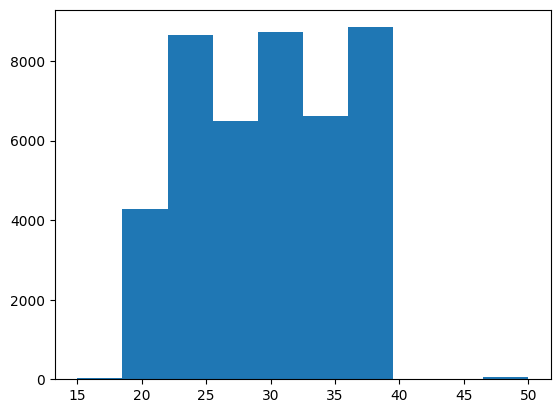

In [429]:
plt.hist(df["Delivery_person_Age"])

<Axes: xlabel='Delivery_person_Age', ylabel='Count'>

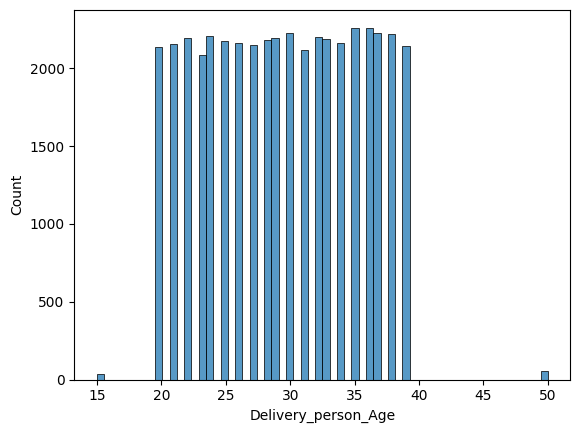

In [430]:
sns.histplot(df["Delivery_person_Age"])

<Axes: ylabel='Delivery_person_Age'>

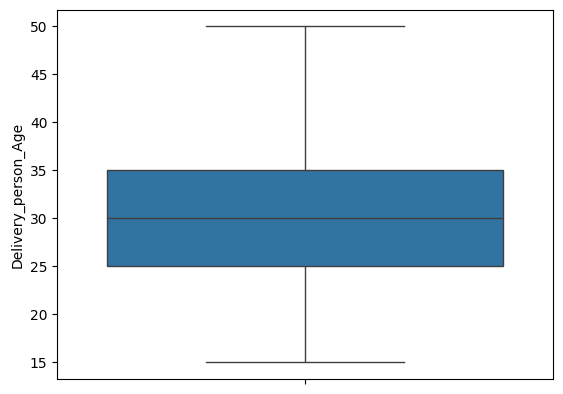

In [431]:
sns.boxplot(df["Delivery_person_Age"])

In [432]:
df["Delivery_person_Age"] = df["Delivery_person_Age"].fillna(round(df["Delivery_person_Age"].mean()))

In [433]:
df["Delivery_person_Age"].isnull().mean()*100

np.float64(0.0)

In [434]:
df.isnull().mean()*100


,0
Delivery_person_Age,0.000000
Delivery_person_Ratings,4.185679
Restaurant_latitude,0.000000
Restaurant_longitude,0.000000
Delivery_location_latitude,0.000000
Delivery_location_longitude,0.000000
Order_Date,0.000000
Time_Orderd,3.797385
Time_Order_picked,0.000000
Weather_conditions,1.351351


In [435]:
df.columns

Index(['Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude',
       'Restaurant_longitude', 'Delivery_location_latitude',
       'Delivery_location_longitude', 'Order_Date', 'Time_Orderd',
       'Time_Order_picked', 'Weather_conditions', 'Road_traffic_density',
       'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle',
       'multiple_deliveries', 'Festival', 'City', 'Time_taken (min)'],
      dtype='object')

In [436]:
df["Delivery_person_Ratings"].isnull().mean()*100

np.float64(4.185679185679185)

In [437]:
df["Delivery_person_Ratings"].value_counts()

,count
Delivery_person_Ratings,
4.8,7146
4.7,7140
4.9,7040
4.6,6938
5.0,3996
4.5,3302
4.1,1430
4.2,1418
4.3,1409


In [438]:
df[df["Delivery_person_Ratings"]>5]


,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min)
3577,50.0,6.0,-12.970324,-77.645748,13.010324,77.685748,13-03-2022,NaN,12:30,NaN,NaN,3,Meal,electric_scooter,0.0,No,Urban,25
4705,50.0,6.0,-17.451976,-78.385883,17.561976,78.495883,04-04-2022,NaN,23:20,NaN,NaN,3,Snack,bicycle,0.0,No,Metropolitian,27
5160,50.0,6.0,-26.910262,-75.783013,27.020262,75.893013,18-03-2022,NaN,18:50,NaN,NaN,3,Drinks,scooter,1.0,No,Metropolitian,20
5353,50.0,6.0,12.914264,77.678400,13.024264,77.788400,06-04-2022,NaN,20:55,NaN,NaN,3,Meal,electric_scooter,1.0,No,Metropolitian,18
5642,50.0,6.0,-27.159795,-78.042990,27.209795,78.092990,13-02-2022,NaN,18:05,NaN,NaN,3,Drinks,scooter,1.0,No,Metropolitian,20
6385,50.0,6.0,26.911927,75.797282,27.041927,75.927282,02-04-2022,NaN,22:10,NaN,NaN,3,Meal,electric_scooter,0.0,No,Urban,20
7022,50.0,6.0,-12.352058,-76.606650,12.372058,76.626650,15-03-2022,NaN,0.416666667,NaN,NaN,3,Buffet,scooter,1.0,No,Metropolitian,14
7672,50.0,6.0,0.000000,0.000000,0.010000,0.010000,21-03-2022,NaN,08:35,NaN,NaN,3,Meal,bicycle,1.0,No,Metropolitian,22
9490,50.0,6.0,12.933298,77.614293,13.003298,77.684293,12-03-2022,NaN,18:25,NaN,NaN,3,Drinks,scooter,1.0,No,Urban,17
9526,50.0,6.0,-23.374989,-85.335486,23.444989,85.405486,20-03-2022,NaN,17:55,NaN,NaN,3,Snack,bicycle,1.0,No,Metropolitian,32


In [439]:
df["Delivery_person_Ratings"] = df["Delivery_person_Ratings"].clip(upper=5)

<Axes: xlabel='Delivery_person_Ratings', ylabel='Count'>

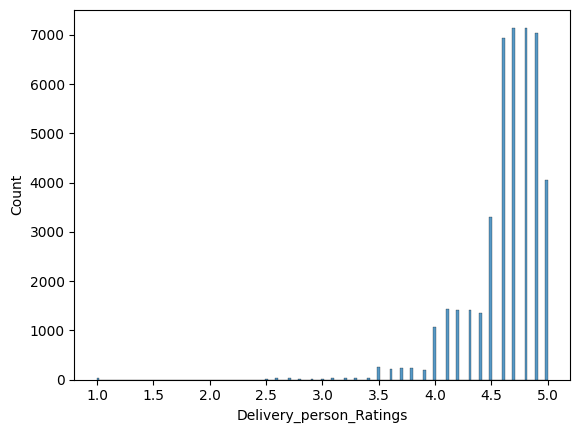

In [440]:
sns.histplot(df['Delivery_person_Ratings'])

In [441]:
df["Delivery_person_Ratings"] = df['Delivery_person_Ratings'].fillna(df["Delivery_person_Ratings"].median())

In [442]:
df["Delivery_person_Ratings"].isnull().mean()*100


np.float64(0.0)

In [443]:
df.isnull().mean()*100

,0
Delivery_person_Age,0.000000
Delivery_person_Ratings,0.000000
Restaurant_latitude,0.000000
Restaurant_longitude,0.000000
Delivery_location_latitude,0.000000
Delivery_location_longitude,0.000000
Order_Date,0.000000
Time_Orderd,3.797385
Time_Order_picked,0.000000
Weather_conditions,1.351351


In [444]:
df.columns

Index(['Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude',
       'Restaurant_longitude', 'Delivery_location_latitude',
       'Delivery_location_longitude', 'Order_Date', 'Time_Orderd',
       'Time_Order_picked', 'Weather_conditions', 'Road_traffic_density',
       'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle',
       'multiple_deliveries', 'Festival', 'City', 'Time_taken (min)'],
      dtype='object')

In [445]:
columns = [
    "Restaurant_latitude",
    "Restaurant_longitude",
    "Delivery_location_latitude",
    "Delivery_location_longitude"
]


zero_rows = (df[columns] == 0).any(axis=1)
df = df[~zero_rows].copy()
print(zero_rows.sum())

3640


In [446]:
df.isnull().mean()*100

,0
Delivery_person_Age,0.000000
Delivery_person_Ratings,0.000000
Restaurant_latitude,0.000000
Restaurant_longitude,0.000000
Delivery_location_latitude,0.000000
Delivery_location_longitude,0.000000
Order_Date,0.000000
Time_Orderd,3.814610
Time_Order_picked,0.000000
Weather_conditions,1.356571


In [447]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 41944 entries, 0 to 45583
Data columns (total 18 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Delivery_person_Age          41944 non-null  float64
 1   Delivery_person_Ratings      41944 non-null  float64
 2   Restaurant_latitude          41944 non-null  float64
 3   Restaurant_longitude         41944 non-null  float64
 4   Delivery_location_latitude   41944 non-null  float64
 5   Delivery_location_longitude  41944 non-null  float64
 6   Order_Date                   41944 non-null  object 
 7   Time_Orderd                  40344 non-null  object 
 8   Time_Order_picked            41944 non-null  object 
 9   Weather_conditions           41375 non-null  object 
 10  Road_traffic_density         41389 non-null  object 
 11  Vehicle_condition            41944 non-null  int64  
 12  Type_of_order                41944 non-null  object 
 13  Type_of_vehicle      

In [448]:
df.select_dtypes(include="float")

,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,multiple_deliveries
0,36.0,4.2,30.327968,78.046106,30.397968,78.116106,3.0
1,21.0,4.7,10.003064,76.307589,10.043064,76.347589,1.0
2,23.0,4.7,18.562450,73.916619,18.652450,74.006619,1.0
3,34.0,4.3,30.899584,75.809346,30.919584,75.829346,0.0
4,24.0,4.7,26.463504,80.372929,26.593504,80.502929,1.0
...,...,...,...,...,...,...,...
45578,35.0,4.2,23.371292,85.327872,23.481292,85.437872,1.0
45579,30.0,4.8,26.902328,75.794257,26.912328,75.804257,0.0
45581,30.0,4.9,13.022394,80.242439,13.052394,80.272439,0.0
45582,20.0,4.7,11.001753,76.986241,11.041753,77.026241,1.0


In [449]:
df.select_dtypes(include="int")

,Vehicle_condition,Time_taken (min)
0,2,46
1,1,23
2,1,21
3,0,20
4,1,41
...,...,...
45578,2,33
45579,1,32
45581,1,16
45582,0,26


In [450]:
df.select_dtypes(include="object")

,Order_Date,Time_Orderd,Time_Order_picked,Weather_conditions,Road_traffic_density,Type_of_order,Type_of_vehicle,Festival,City
0,12-02-2022,21:55,22:10,Fog,Jam,Snack,motorcycle,No,Metropolitian
1,13-02-2022,14:55,15:05,Stormy,High,Meal,motorcycle,No,Metropolitian
2,04-03-2022,17:30,17:40,Sandstorms,Medium,Drinks,scooter,No,Metropolitian
3,13-02-2022,09:20,09:30,Sandstorms,Low,Buffet,motorcycle,No,Metropolitian
4,14-02-2022,19:50,20:05,Fog,Jam,Snack,scooter,No,Metropolitian
...,...,...,...,...,...,...,...,...,...
45578,08-03-2022,21:45,21:55,Windy,Jam,Drinks,motorcycle,No,Metropolitian
45579,24-03-2022,11:35,11:45,Windy,High,Meal,motorcycle,No,Metropolitian
45581,11-03-2022,23:50,24:05:00,Cloudy,Low,Drinks,scooter,No,Metropolitian
45582,07-03-2022,13:35,13:40,Cloudy,High,Snack,motorcycle,No,Metropolitian


In [451]:
df["multiple_deliveries"] = df["multiple_deliveries"].fillna(df["multiple_deliveries"].median())

In [452]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 41944 entries, 0 to 45583
Data columns (total 18 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Delivery_person_Age          41944 non-null  float64
 1   Delivery_person_Ratings      41944 non-null  float64
 2   Restaurant_latitude          41944 non-null  float64
 3   Restaurant_longitude         41944 non-null  float64
 4   Delivery_location_latitude   41944 non-null  float64
 5   Delivery_location_longitude  41944 non-null  float64
 6   Order_Date                   41944 non-null  object 
 7   Time_Orderd                  40344 non-null  object 
 8   Time_Order_picked            41944 non-null  object 
 9   Weather_conditions           41375 non-null  object 
 10  Road_traffic_density         41389 non-null  object 
 11  Vehicle_condition            41944 non-null  int64  
 12  Type_of_order                41944 non-null  object 
 13  Type_of_vehicle      

In [453]:
df.describe()

,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Vehicle_condition,multiple_deliveries,Time_taken (min)
count,41944.000000,41944.000000,41944.000000,41944.000000,41944.000000,41944.000000,41944.000000,41944.000000,41944.000000
mean,29.580989,4.634124,18.494806,76.324383,18.975707,76.986717,1.022745,0.750715,26.310843
std,5.692568,0.325823,6.745770,10.198903,5.469655,3.503144,0.838883,0.567195,9.381288
min,15.000000,1.000000,-30.905562,-88.366217,9.967144,72.778726,0.000000,0.000000,10.000000
25%,25.000000,4.500000,12.980410,73.897902,13.065996,73.940327,0.000000,0.000000,19.000000
50%,30.000000,4.700000,19.003517,76.618203,19.124049,76.663067,1.000000,1.000000,26.000000
75%,34.000000,4.800000,22.750040,78.347554,22.820040,78.405467,2.000000,1.000000,32.000000
max,50.000000,5.000000,30.914057,88.433452,31.054057,88.563452,3.000000,3.000000,54.000000


In [454]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 41944 entries, 0 to 45583
Data columns (total 18 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Delivery_person_Age          41944 non-null  float64
 1   Delivery_person_Ratings      41944 non-null  float64
 2   Restaurant_latitude          41944 non-null  float64
 3   Restaurant_longitude         41944 non-null  float64
 4   Delivery_location_latitude   41944 non-null  float64
 5   Delivery_location_longitude  41944 non-null  float64
 6   Order_Date                   41944 non-null  object 
 7   Time_Orderd                  40344 non-null  object 
 8   Time_Order_picked            41944 non-null  object 
 9   Weather_conditions           41375 non-null  object 
 10  Road_traffic_density         41389 non-null  object 
 11  Vehicle_condition            41944 non-null  int64  
 12  Type_of_order                41944 non-null  object 
 13  Type_of_vehicle      

In [455]:
df["Road_traffic_density"].value_counts()

,count
Road_traffic_density,
Low,14199
Jam,13039
Medium,10082
High,4069


In [456]:
df["Weather_conditions"].value_counts()

,count
Weather_conditions,
Fog,7011
Stormy,6972
Cloudy,6929
Sandstorms,6905
Windy,6832
Sunny,6726


In [457]:
df["Weather_conditions"] = df["Weather_conditions"].fillna(df["Weather_conditions"].mode()[0])

In [458]:
df["Road_traffic_density"] = df['Road_traffic_density'].fillna(df['Road_traffic_density'].mode()[0])

In [459]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 41944 entries, 0 to 45583
Data columns (total 18 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Delivery_person_Age          41944 non-null  float64
 1   Delivery_person_Ratings      41944 non-null  float64
 2   Restaurant_latitude          41944 non-null  float64
 3   Restaurant_longitude         41944 non-null  float64
 4   Delivery_location_latitude   41944 non-null  float64
 5   Delivery_location_longitude  41944 non-null  float64
 6   Order_Date                   41944 non-null  object 
 7   Time_Orderd                  40344 non-null  object 
 8   Time_Order_picked            41944 non-null  object 
 9   Weather_conditions           41944 non-null  object 
 10  Road_traffic_density         41944 non-null  object 
 11  Vehicle_condition            41944 non-null  int64  
 12  Type_of_order                41944 non-null  object 
 13  Type_of_vehicle      

In [460]:
df["Festival"] = df["Festival"].fillna(df["Festival"].mode()[0])
df["City"] = df["City"].fillna(df["City"].mode()[0])

In [461]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 41944 entries, 0 to 45583
Data columns (total 18 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Delivery_person_Age          41944 non-null  float64
 1   Delivery_person_Ratings      41944 non-null  float64
 2   Restaurant_latitude          41944 non-null  float64
 3   Restaurant_longitude         41944 non-null  float64
 4   Delivery_location_latitude   41944 non-null  float64
 5   Delivery_location_longitude  41944 non-null  float64
 6   Order_Date                   41944 non-null  object 
 7   Time_Orderd                  40344 non-null  object 
 8   Time_Order_picked            41944 non-null  object 
 9   Weather_conditions           41944 non-null  object 
 10  Road_traffic_density         41944 non-null  object 
 11  Vehicle_condition            41944 non-null  int64  
 12  Type_of_order                41944 non-null  object 
 13  Type_of_vehicle      

**EDA**

In [462]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 41944 entries, 0 to 45583
Data columns (total 18 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Delivery_person_Age          41944 non-null  float64
 1   Delivery_person_Ratings      41944 non-null  float64
 2   Restaurant_latitude          41944 non-null  float64
 3   Restaurant_longitude         41944 non-null  float64
 4   Delivery_location_latitude   41944 non-null  float64
 5   Delivery_location_longitude  41944 non-null  float64
 6   Order_Date                   41944 non-null  object 
 7   Time_Orderd                  40344 non-null  object 
 8   Time_Order_picked            41944 non-null  object 
 9   Weather_conditions           41944 non-null  object 
 10  Road_traffic_density         41944 non-null  object 
 11  Vehicle_condition            41944 non-null  int64  
 12  Type_of_order                41944 non-null  object 
 13  Type_of_vehicle      

target

In [463]:
df["Time_taken (min)"].describe()

,Time_taken (min)
count,41944.000000
mean,26.310843
std,9.381288
min,10.000000
25%,19.000000
50%,26.000000
75%,32.000000
max,54.000000


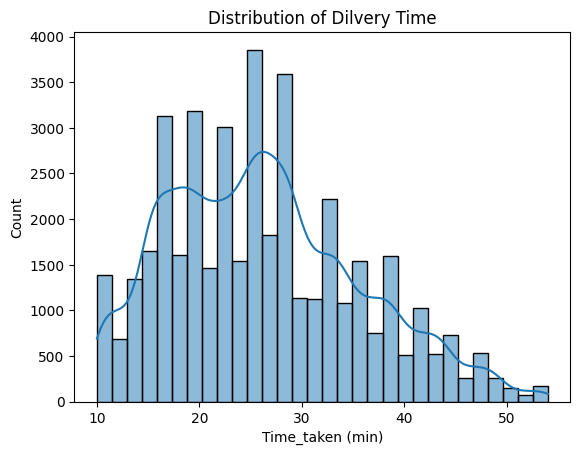

In [464]:
sns.histplot(df["Time_taken (min)"],bins=30,kde=True)
plt.title("Distribution of Dilvery Time")
plt.show()

Input Features

Categorical Columns

In [465]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 41944 entries, 0 to 45583
Data columns (total 18 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Delivery_person_Age          41944 non-null  float64
 1   Delivery_person_Ratings      41944 non-null  float64
 2   Restaurant_latitude          41944 non-null  float64
 3   Restaurant_longitude         41944 non-null  float64
 4   Delivery_location_latitude   41944 non-null  float64
 5   Delivery_location_longitude  41944 non-null  float64
 6   Order_Date                   41944 non-null  object 
 7   Time_Orderd                  40344 non-null  object 
 8   Time_Order_picked            41944 non-null  object 
 9   Weather_conditions           41944 non-null  object 
 10  Road_traffic_density         41944 non-null  object 
 11  Vehicle_condition            41944 non-null  int64  
 12  Type_of_order                41944 non-null  object 
 13  Type_of_vehicle      

In [466]:
df["Road_traffic_density"].value_counts()

,count
Road_traffic_density,
Low,14754
Jam,13039
Medium,10082
High,4069


In [467]:
df.groupby("Road_traffic_density")['Time_taken (min)'].agg(['count','mean','median','std','min','max'])

,count,mean,median,std,min,max
Road_traffic_density,,,,,,
High,4069,27.226591,27.0,8.417643,10,54
Jam,13039,31.182453,31.0,9.938162,10,54
Low,14754,21.468890,21.0,6.995211,10,54
Medium,10082,26.726542,27.0,8.526851,10,49


In [468]:
df.groupby('Weather_conditions')['Time_taken (min)'].agg(['count','mean','median','std','min','max'])

,count,mean,median,std,min,max
Weather_conditions,,,,,,
Cloudy,6929,28.925819,29.0,10.025213,10,54
Fog,7580,28.775330,28.0,10.097757,10,54
Sandstorms,6905,25.880956,26.0,8.638938,10,54
Stormy,6972,25.894578,26.0,8.488472,10,54
Sunny,6726,21.897116,20.0,8.358766,10,54
Windy,6832,26.128952,26.0,8.620934,10,54


In [469]:
df.columns

Index(['Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude',
       'Restaurant_longitude', 'Delivery_location_latitude',
       'Delivery_location_longitude', 'Order_Date', 'Time_Orderd',
       'Time_Order_picked', 'Weather_conditions', 'Road_traffic_density',
       'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle',
       'multiple_deliveries', 'Festival', 'City', 'Time_taken (min)'],
      dtype='object')

In [470]:
df["Festival"].value_counts()

,count
Festival,
No,41122
Yes,822


In [471]:
df.groupby("Festival")["Time_taken (min)"].agg(['count','mean','median','std','min','max'])

,count,mean,median,std,min,max
Festival,,,,,,
No,41122,25.927679,25.0,9.052846,10,54
Yes,822,45.479319,45.0,4.016887,38,54


In [472]:
df.groupby("City")["Time_taken (min)"].agg(['count','mean','median','std','min','max'])

,count,mean,median,std,min,max
City,,,,,,
Metropolitian,32519,27.141302,26.0,9.206783,10,54
Semi-Urban,149,49.677852,49.0,2.731865,44,54
Urban,9276,23.024148,22.0,8.870853,10,54


In [473]:
df.groupby("Type_of_vehicle")["Time_taken (min)"].agg(['count','mean','median','std','min','max'])

,count,mean,median,std,min,max
Type_of_vehicle,,,,,,
bicycle,60,26.416667,26.5,8.959971,10,47
electric_scooter,3468,24.460208,24.0,8.642759,10,53
motorcycle,24390,27.609307,26.0,9.638771,10,54
scooter,14026,24.510053,24.0,8.707016,10,54


In [474]:
df.columns

Index(['Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude',
       'Restaurant_longitude', 'Delivery_location_latitude',
       'Delivery_location_longitude', 'Order_Date', 'Time_Orderd',
       'Time_Order_picked', 'Weather_conditions', 'Road_traffic_density',
       'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle',
       'multiple_deliveries', 'Festival', 'City', 'Time_taken (min)'],
      dtype='object')

In [475]:
df.groupby("Type_of_order")["Time_taken (min)"].agg(['count','mean','median','std','min','max'])

,count,mean,median,std,min,max
Type_of_order,,,,,,
Buffet,10365,26.239653,25.0,9.387056,10,54
Drinks,10444,26.193891,25.0,9.290457,10,54
Meal,10522,26.484984,26.0,9.425601,10,54
Snack,10613,26.322812,26.0,9.419227,10,54


Numerical Features


In [476]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 41944 entries, 0 to 45583
Data columns (total 18 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Delivery_person_Age          41944 non-null  float64
 1   Delivery_person_Ratings      41944 non-null  float64
 2   Restaurant_latitude          41944 non-null  float64
 3   Restaurant_longitude         41944 non-null  float64
 4   Delivery_location_latitude   41944 non-null  float64
 5   Delivery_location_longitude  41944 non-null  float64
 6   Order_Date                   41944 non-null  object 
 7   Time_Orderd                  40344 non-null  object 
 8   Time_Order_picked            41944 non-null  object 
 9   Weather_conditions           41944 non-null  object 
 10  Road_traffic_density         41944 non-null  object 
 11  Vehicle_condition            41944 non-null  int64  
 12  Type_of_order                41944 non-null  object 
 13  Type_of_vehicle      

In [477]:
df['Delivery_person_Age'].describe()

,Delivery_person_Age
count,41944.000000
mean,29.580989
std,5.692568
min,15.000000
25%,25.000000
50%,30.000000
75%,34.000000
max,50.000000


<Axes: xlabel='Delivery_person_Age', ylabel='Count'>

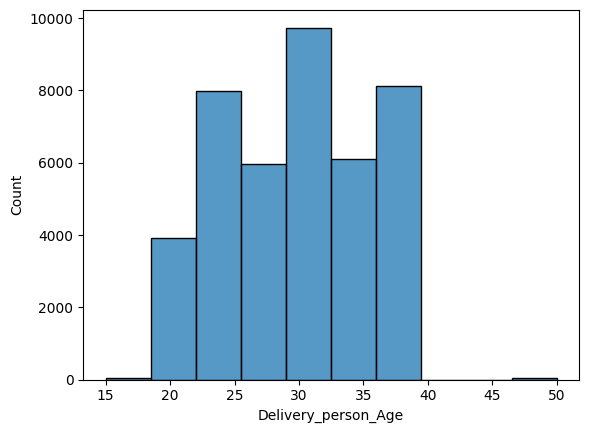

In [478]:
sns.histplot(df['Delivery_person_Age'],bins=10)

In [479]:
df[df['Delivery_person_Age']>40]["Delivery_person_Age"].shape

(46,)

<Axes: xlabel='Delivery_person_Age', ylabel='Time_taken (min)'>

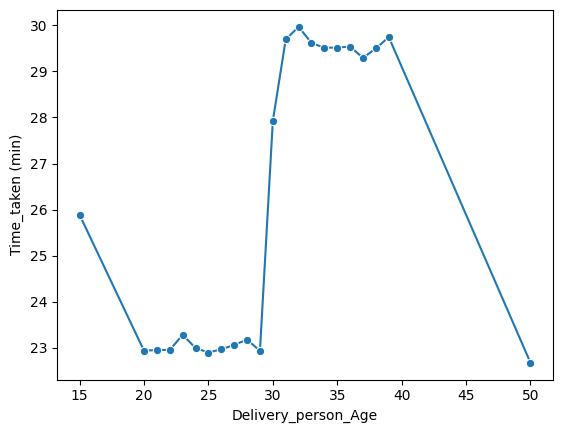

In [480]:
sns.lineplot(
    data = df,
    x="Delivery_person_Age",
    y="Time_taken (min)",
    estimator="mean",
    errorbar=None,
    marker="o"
)

In [481]:
df["Delivery_person_Ratings"].describe()

,Delivery_person_Ratings
count,41944.000000
mean,4.634124
std,0.325823
min,1.000000
25%,4.500000
50%,4.700000
75%,4.800000
max,5.000000


<Axes: xlabel='Delivery_person_Ratings', ylabel='Time_taken (min)'>

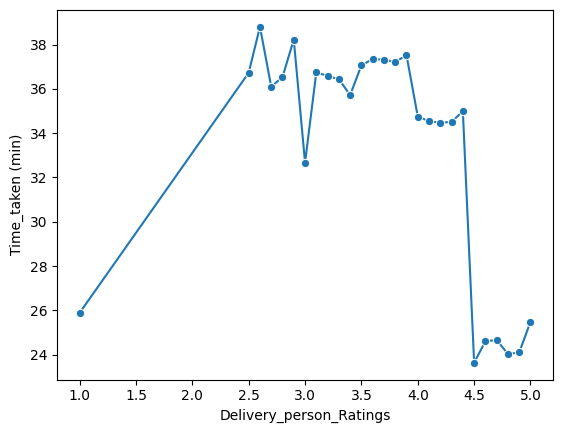

In [482]:
sns.lineplot(
    data = df,
    x="Delivery_person_Ratings",
    y="Time_taken (min)",
    estimator="mean",
    errorbar=None,
    marker="o"
)

In [483]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 41944 entries, 0 to 45583
Data columns (total 18 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Delivery_person_Age          41944 non-null  float64
 1   Delivery_person_Ratings      41944 non-null  float64
 2   Restaurant_latitude          41944 non-null  float64
 3   Restaurant_longitude         41944 non-null  float64
 4   Delivery_location_latitude   41944 non-null  float64
 5   Delivery_location_longitude  41944 non-null  float64
 6   Order_Date                   41944 non-null  object 
 7   Time_Orderd                  40344 non-null  object 
 8   Time_Order_picked            41944 non-null  object 
 9   Weather_conditions           41944 non-null  object 
 10  Road_traffic_density         41944 non-null  object 
 11  Vehicle_condition            41944 non-null  int64  
 12  Type_of_order                41944 non-null  object 
 13  Type_of_vehicle      

Text(0.5, 1.0, 'Correlation')

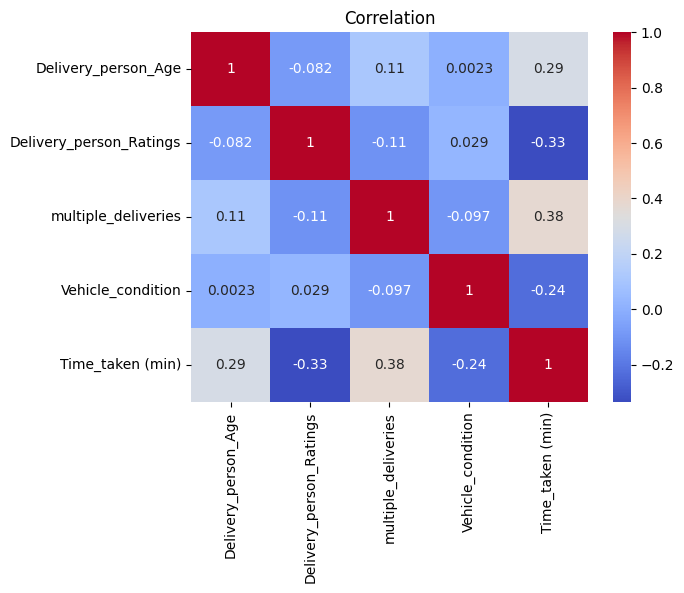

In [484]:
numeric_cols = [
    'Delivery_person_Age',
    'Delivery_person_Ratings',
    'multiple_deliveries',
    'Vehicle_condition',
    'Time_taken (min)'
]
sns.heatmap(df[numeric_cols].corr(),annot=True,cmap="coolwarm")
plt.title('Correlation')

DATE FEATURE

In [485]:
df['Order_Date'][2]

'04-03-2022'

In [486]:
df['Time_Orderd']

,Time_Orderd
0,21:55
1,14:55
2,17:30
3,09:20
4,19:50
...,...
45578,21:45
45579,11:35
45581,23:50
45582,13:35


In [487]:
hour = pd.to_datetime(df['Time_Orderd'].str.strip(), format='%H:%M', errors='coerce').dt.hour

In [488]:
hour.unique()

array([21., 14., 17.,  9., 19., 20., 22.,  8., 12., 18., 23., 13., nan,
       10., 16., 11., 15.])

In [489]:
hour.describe()

,Time_Orderd
count,36615.000000
mean,17.573017
std,4.521667
min,8.000000
25%,15.000000
50%,19.000000
75%,21.000000
max,23.000000


In [490]:
df.groupby(hour)["Time_taken (min)"].agg(['count','mean','median','std'])

,count,mean,median,std
Time_Orderd,,,,
8.0,1675,19.647164,19.0,5.640487
9.0,1625,19.524308,19.0,5.539340
10.0,1633,19.492958,19.0,5.514918
11.0,1626,27.216482,27.0,8.215026
12.0,651,26.798771,27.0,8.777299
13.0,645,27.474419,27.0,8.775215
14.0,660,27.312121,27.0,8.243791
15.0,721,22.962552,23.0,6.774133
16.0,603,23.107794,24.0,6.764672


In [491]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 41944 entries, 0 to 45583
Data columns (total 18 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Delivery_person_Age          41944 non-null  float64
 1   Delivery_person_Ratings      41944 non-null  float64
 2   Restaurant_latitude          41944 non-null  float64
 3   Restaurant_longitude         41944 non-null  float64
 4   Delivery_location_latitude   41944 non-null  float64
 5   Delivery_location_longitude  41944 non-null  float64
 6   Order_Date                   41944 non-null  object 
 7   Time_Orderd                  40344 non-null  object 
 8   Time_Order_picked            41944 non-null  object 
 9   Weather_conditions           41944 non-null  object 
 10  Road_traffic_density         41944 non-null  object 
 11  Vehicle_condition            41944 non-null  int64  
 12  Type_of_order                41944 non-null  object 
 13  Type_of_vehicle      

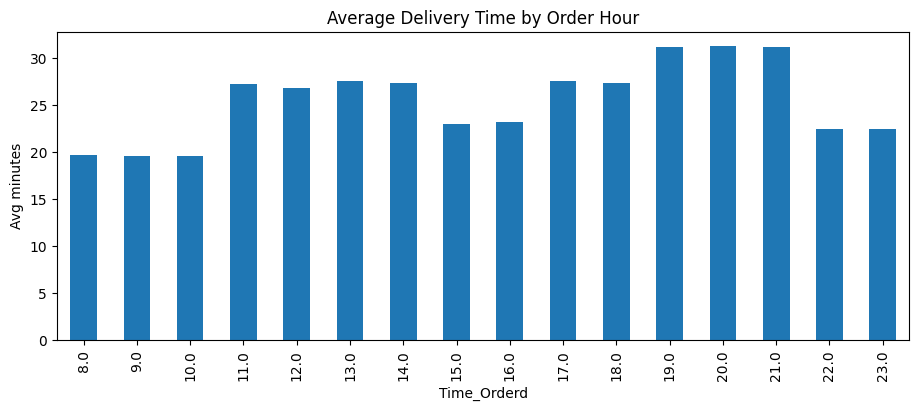

In [492]:
df.groupby(hour)['Time_taken (min)'].mean().plot(kind='bar', figsize=(11,4))
plt.title('Average Delivery Time by Order Hour')
plt.ylabel('Avg minutes')
plt.show()

Feature Eng

In [493]:

df.columns

Index(['Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude',
       'Restaurant_longitude', 'Delivery_location_latitude',
       'Delivery_location_longitude', 'Order_Date', 'Time_Orderd',
       'Time_Order_picked', 'Weather_conditions', 'Road_traffic_density',
       'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle',
       'multiple_deliveries', 'Festival', 'City', 'Time_taken (min)'],
      dtype='object')

In [494]:
def haversine_distance(lat1, lon1, lat2, lon2):
    # Convert decimal degrees to radians
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])

    # Haversine formula
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2.0)**2
    c = 2 * np.arcsin(np.sqrt(a))

    # Radius of Earth in kilometers
    km = 6371.0
    return c * km

# Calculate distance and store it in distance_km
df['distance_km'] = haversine_distance(
    df['Restaurant_latitude'],
    df['Restaurant_longitude'],
    df['Delivery_location_latitude'],
    df['Delivery_location_longitude']
)

# Display the updated DataFrame statistics for the new feature
print(df['distance_km'].describe())

count    41944.000000
mean       107.080686
std       1146.240729
min          1.465067
25%          4.658001
50%          9.220368
75%         13.760880
max      19692.674606
Name: distance_km, dtype: float64


In [495]:
df["distance_km"].describe()

,distance_km
count,41944.000000
mean,107.080686
std,1146.240729
min,1.465067
25%,4.658001
50%,9.220368
75%,13.760880
max,19692.674606


In [496]:
df[df['distance_km']>100]["distance_km"].describe()

,distance_km
count,431.000000
mean,9484.671093
std,6252.618252
min,2216.065794
25%,4434.856783
50%,5897.015762
75%,17132.390571
max,19692.674606


In [497]:
df[df['distance_km']<100]["distance_km"].describe()

,distance_km
count,41513.000000
mean,9.719824
std,5.602505
min,1.465067
25%,4.657655
50%,9.193021
75%,13.680920
max,20.969489


In [498]:
df[df['distance_km']>100]

,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min),distance_km
83,34.0,4.7,-27.163303,78.057044,27.233303,78.127044,16-02-2022,0.958333333,23:05,Sandstorms,Low,1,Drinks,scooter,0.0,No,Metropolitian,15,6048.631240
274,32.0,4.7,-27.165108,78.015053,27.225108,78.075053,13-02-2022,20:55,21:10,Sandstorms,Jam,2,Meal,scooter,1.0,No,Metropolitian,31,6047.919478
280,30.0,4.7,-18.551440,-73.804855,18.611440,73.864855,05-03-2022,NaN,22:05,Stormy,Jam,2,Meal,scooter,0.0,No,Urban,12,16612.239055
416,30.0,4.7,-30.366322,-78.070453,30.496322,78.200453,18-02-2022,NaN,22:30,Fog,Low,3,Snack,scooter,1.0,No,Metropolitian,20,17744.205087
525,30.0,4.7,-12.325461,-76.632278,12.385461,76.692278,03-03-2022,NaN,22:45,Fog,Low,3,Buffet,scooter,1.0,No,Metropolitian,16,17118.828366
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44924,30.0,4.9,-19.874733,75.353942,19.904733,75.383942,15-02-2022,22:20,22:35,Fog,Low,1,Buffet,motorcycle,0.0,No,Metropolitian,15,4423.276011
45011,30.0,4.7,-18.514210,73.838429,18.524210,73.848429,21-03-2022,NaN,12:05,Fog,Low,3,Drinks,electric_scooter,1.0,No,Metropolitian,30,4118.484540
45099,30.0,4.7,-15.493950,-73.827423,15.563950,73.897423,16-02-2022,NaN,22:05,Windy,Jam,2,Meal,scooter,1.0,No,Urban,19,16560.629487
45173,30.0,4.0,-26.482581,80.315628,26.532581,80.365628,17-02-2022,22:25,22:40,Sandstorms,Low,0,Drinks,motorcycle,1.0,No,Metropolitian,34,5895.019482


In [499]:
df = df[df['distance_km']<100].reset_index(drop=True)

In [500]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41513 entries, 0 to 41512
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Delivery_person_Age          41513 non-null  float64
 1   Delivery_person_Ratings      41513 non-null  float64
 2   Restaurant_latitude          41513 non-null  float64
 3   Restaurant_longitude         41513 non-null  float64
 4   Delivery_location_latitude   41513 non-null  float64
 5   Delivery_location_longitude  41513 non-null  float64
 6   Order_Date                   41513 non-null  object 
 7   Time_Orderd                  40188 non-null  object 
 8   Time_Order_picked            41513 non-null  object 
 9   Weather_conditions           41513 non-null  object 
 10  Road_traffic_density         41513 non-null  object 
 11  Vehicle_condition            41513 non-null  int64  
 12  Type_of_order                41513 non-null  object 
 13  Type_of_vehicle 

In [501]:
df['order_hour'] = pd.to_datetime(df['Time_Orderd'],format='%H:%M:%S',errors = 'coerce').dt.hour


In [502]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41513 entries, 0 to 41512
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Delivery_person_Age          41513 non-null  float64
 1   Delivery_person_Ratings      41513 non-null  float64
 2   Restaurant_latitude          41513 non-null  float64
 3   Restaurant_longitude         41513 non-null  float64
 4   Delivery_location_latitude   41513 non-null  float64
 5   Delivery_location_longitude  41513 non-null  float64
 6   Order_Date                   41513 non-null  object 
 7   Time_Orderd                  40188 non-null  object 
 8   Time_Order_picked            41513 non-null  object 
 9   Weather_conditions           41513 non-null  object 
 10  Road_traffic_density         41513 non-null  object 
 11  Vehicle_condition            41513 non-null  int64  
 12  Type_of_order                41513 non-null  object 
 13  Type_of_vehicle 

In [503]:
df['order_hour'] = pd.to_datetime(df['Time_Orderd'],format='%H:%M',errors='coerce').dt.hour

In [504]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41513 entries, 0 to 41512
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Delivery_person_Age          41513 non-null  float64
 1   Delivery_person_Ratings      41513 non-null  float64
 2   Restaurant_latitude          41513 non-null  float64
 3   Restaurant_longitude         41513 non-null  float64
 4   Delivery_location_latitude   41513 non-null  float64
 5   Delivery_location_longitude  41513 non-null  float64
 6   Order_Date                   41513 non-null  object 
 7   Time_Orderd                  40188 non-null  object 
 8   Time_Order_picked            41513 non-null  object 
 9   Weather_conditions           41513 non-null  object 
 10  Road_traffic_density         41513 non-null  object 
 11  Vehicle_condition            41513 non-null  int64  
 12  Type_of_order                41513 non-null  object 
 13  Type_of_vehicle 

In [505]:
df['order_hour'] = df['order_hour'].fillna(df['order_hour'].median())

In [506]:
df['order_hour'].isnull().mean()*100

np.float64(0.0)

In [507]:
sorted(df['order_hour'].unique())

[np.float64(8.0),
 np.float64(9.0),
 np.float64(10.0),
 np.float64(11.0),
 np.float64(12.0),
 np.float64(13.0),
 np.float64(14.0),
 np.float64(15.0),
 np.float64(16.0),
 np.float64(17.0),
 np.float64(18.0),
 np.float64(19.0),
 np.float64(20.0),
 np.float64(21.0),
 np.float64(22.0),
 np.float64(23.0)]

In [508]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41513 entries, 0 to 41512
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Delivery_person_Age          41513 non-null  float64
 1   Delivery_person_Ratings      41513 non-null  float64
 2   Restaurant_latitude          41513 non-null  float64
 3   Restaurant_longitude         41513 non-null  float64
 4   Delivery_location_latitude   41513 non-null  float64
 5   Delivery_location_longitude  41513 non-null  float64
 6   Order_Date                   41513 non-null  object 
 7   Time_Orderd                  40188 non-null  object 
 8   Time_Order_picked            41513 non-null  object 
 9   Weather_conditions           41513 non-null  object 
 10  Road_traffic_density         41513 non-null  object 
 11  Vehicle_condition            41513 non-null  int64  
 12  Type_of_order                41513 non-null  object 
 13  Type_of_vehicle 

In [509]:
df.columns

Index(['Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude',
       'Restaurant_longitude', 'Delivery_location_latitude',
       'Delivery_location_longitude', 'Order_Date', 'Time_Orderd',
       'Time_Order_picked', 'Weather_conditions', 'Road_traffic_density',
       'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle',
       'multiple_deliveries', 'Festival', 'City', 'Time_taken (min)',
       'distance_km', 'order_hour'],
      dtype='object')

In [510]:
features = [
    'Delivery_person_Age', 'Delivery_person_Ratings','distance_km','order_hour','Weather_conditions',
        'Road_traffic_density',
       'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle',
       'multiple_deliveries', 'Festival', 'City'

]



In [511]:
X=df[features]

In [530]:
y = df['Time_taken (min)']

encoding


In [514]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41513 entries, 0 to 41512
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Delivery_person_Age          41513 non-null  float64
 1   Delivery_person_Ratings      41513 non-null  float64
 2   Restaurant_latitude          41513 non-null  float64
 3   Restaurant_longitude         41513 non-null  float64
 4   Delivery_location_latitude   41513 non-null  float64
 5   Delivery_location_longitude  41513 non-null  float64
 6   Order_Date                   41513 non-null  object 
 7   Time_Orderd                  40188 non-null  object 
 8   Time_Order_picked            41513 non-null  object 
 9   Weather_conditions           41513 non-null  object 
 10  Road_traffic_density         41513 non-null  object 
 11  Vehicle_condition            41513 non-null  int64  
 12  Type_of_order                41513 non-null  object 
 13  Type_of_vehicle 

In [523]:
X = df[features].copy()

traffic_mapping = {
    'Low': 0,
    'Medium': 1,
    'High': 2,
    'Jam': 3
}

X['Road_traffic_density'] = X['Road_traffic_density'].map(traffic_mapping)


In [522]:
X['Road_traffic_density']

,Road_traffic_density
0,3
1,2
2,1
3,0
4,3
...,...
41508,3
41509,2
41510,0
41511,2


In [524]:
cols_to_encode = ['Type_of_order', 'Type_of_vehicle', 'Festival', 'City', 'Weather_conditions']
X = pd.get_dummies(X, columns=cols_to_encode, drop_first=True, dtype=int)
display(X.head())

,Delivery_person_Age,Delivery_person_Ratings,distance_km,order_hour,Road_traffic_density,Vehicle_condition,multiple_deliveries,Type_of_order_Drinks,Type_of_order_Meal,Type_of_order_Snack,...,Type_of_vehicle_motorcycle,Type_of_vehicle_scooter,Festival_Yes,City_Semi-Urban,City_Urban,Weather_conditions_Fog,Weather_conditions_Sandstorms,Weather_conditions_Stormy,Weather_conditions_Sunny,Weather_conditions_Windy
0,36.0,4.2,10.280582,21.0,3,2,3.0,0,0,1,...,1,0,0,0,0,1,0,0,0,0
1,21.0,4.7,6.242319,14.0,2,1,1.0,0,1,0,...,1,0,0,0,0,0,0,1,0,0
2,23.0,4.7,13.787860,17.0,1,1,1.0,1,0,0,...,0,1,0,0,0,0,1,0,0,0
3,34.0,4.3,2.930258,9.0,0,0,0.0,0,0,0,...,1,0,0,0,0,0,1,0,0,0
4,24.0,4.7,19.396618,19.0,3,1,1.0,0,0,1,...,0,1,0,0,0,1,0,0,0,0


In [528]:
from sklearn.model_selection import train_test_split

In [532]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [535]:
X_train.shape,X_test.shape

((33210, 21), (8303, 21))

feature scaling

In [536]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [538]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [539]:
X_train_scaled

array([[ 0.24828043,  0.5157453 ,  0.48285104, ...,  2.23026816,
        -0.436993  , -0.44391296],
       [ 0.24828043,  0.5157453 , -1.46366943, ..., -0.44837658,
        -0.436993  , -0.44391296],
       [-1.50878761,  1.13852146,  0.44267567, ..., -0.44837658,
        -0.436993  , -0.44391296],
       ...,
       [-0.80596039,  0.20435722,  1.73696912, ..., -0.44837658,
        -0.436993  , -0.44391296],
       [ 1.30252126,  0.82713338, -1.19448226, ..., -0.44837658,
        -0.436993  , -0.44391296],
       [-0.9816672 ,  0.20435722,  0.72015018, ..., -0.44837658,
        -0.436993  , -0.44391296]])

In [540]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

In [544]:
import joblib
joblib.dump(scaler,'standard_scaler.pkl')

['standard_scaler.pkl']

In [545]:
from sklearn.linear_model import  LinearRegression

In [546]:
lr = LinearRegression()

In [547]:
lr.fit(X_train_scaled,y_train)

LinearRegression()

In [548]:
lr.coef_

array([ 2.26103266, -2.22246481,  2.14927575, -0.59993212,  2.9055172 ,
       -1.76645485,  1.67662929, -0.02838887,  0.04201991, -0.01011297,
       -0.2664929 , -0.66207141, -0.88305568,  1.34139807,  0.5626865 ,
       -0.77678124,  0.09525655, -1.03287618, -1.06522081, -2.28226083,
       -0.98957969])

In [549]:
X_train.columns

Index(['Delivery_person_Age', 'Delivery_person_Ratings', 'distance_km',
       'order_hour', 'Road_traffic_density', 'Vehicle_condition',
       'multiple_deliveries', 'Type_of_order_Drinks', 'Type_of_order_Meal',
       'Type_of_order_Snack', 'Type_of_vehicle_electric_scooter',
       'Type_of_vehicle_motorcycle', 'Type_of_vehicle_scooter', 'Festival_Yes',
       'City_Semi-Urban', 'City_Urban', 'Weather_conditions_Fog',
       'Weather_conditions_Sandstorms', 'Weather_conditions_Stormy',
       'Weather_conditions_Sunny', 'Weather_conditions_Windy'],
      dtype='object')

In [550]:
from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error,root_mean_squared_error

In [551]:
y_pred_test = lr.predict(X_test_scaled)

In [559]:
y_pred_train = lr.predict(X_train_scaled)
print("LR TRAIN")
print("MAE : ", mean_absolute_error(y_train, y_pred_train))
print("MSE : ", mean_squared_error(y_train, y_pred_train))
print("RMSE : ", root_mean_squared_error(y_train, y_pred_train))
print("R2 : ", r2_score(y_train, y_pred_train))

TRAIN
MAE :  4.863039313993452
MSE :  36.979994484422335
RMSE :  6.081117864704017
R2 :  0.5806961492872169


In [556]:
print("LR TEST")
print("MAE : ", mean_absolute_error(y_test, y_pred_test))
print("MSE : ", mean_squared_error(y_test, y_pred_test))
print("RMSE : ", root_mean_squared_error(y_test, y_pred_test))
print("R2 : ", r2_score(y_test, y_pred_test))

TEST
MAE :  4.7938825194598085
MSE :  36.17877651251742
RMSE :  6.014879592520321
R2 :  0.5853091150619705


In [557]:
y_pred_train = lr.predict(X_train_scaled)

In [561]:
from sklearn.tree import DecisionTreeRegressor

In [562]:
dt = DecisionTreeRegressor(random_state=42)


In [563]:
dt.fit(X_train_scaled, y_train)

y_pred_dt_train = dt.predict(X_train_scaled)
y_pred_dt_test = dt.predict(X_test_scaled)

In [564]:
print("DT TRAIN")
print("MAE : ", mean_absolute_error(y_train, y_pred_dt_train))
print("MSE : ", mean_squared_error(y_train, y_pred_dt_train))
print("RMSE : ", root_mean_squared_error(y_train, y_pred_dt_train))
print("R2 : ", r2_score(y_train, y_pred_dt_train))

print("\nDT TEST")
print("MAE : ", mean_absolute_error(y_test, y_pred_dt_test))
print("MSE : ", mean_squared_error(y_test, y_pred_dt_test))
print("RMSE : ", root_mean_squared_error(y_test, y_pred_dt_test))
print("R2 : ", r2_score(y_test, y_pred_dt_test))

DECISION TREE TRAIN
MAE :  0.0
MSE :  0.0
RMSE :  0.0
R2 :  1.0

DECISION TREE TEST
MAE :  4.151752378658316
MSE :  30.13778152475009
RMSE :  5.489788841544827
R2 :  0.6545526273879521


In [ ]:
from sklearn.ensemble import RandomForestRegressor

In [572]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100,random_state=42)
rf.fit(X_train_scaled, y_train)

y_pred_rf_train = rf.predict(X_train_scaled)
y_pred_rf_test = rf.predict(X_test_scaled)

In [573]:
print("RF TRAIN")
print("MAE : ", mean_absolute_error(y_train, y_pred_rf_train))
print("MSE : ", mean_squared_error(y_train, y_pred_rf_train))
print('RMSE : ', root_mean_squared_error(y_train, y_pred_rf_train))
print('R2 : ', r2_score(y_train, y_pred_rf_train))

print("\nRF TEST")
print("MAE : ", mean_absolute_error(y_test, y_pred_rf_test))
print("MSE : ", mean_squared_error(y_test, y_pred_rf_test))
print('RMSE : ', root_mean_squared_error(y_test, y_pred_rf_test))
print('R2 : ', r2_score(y_test, y_pred_rf_test))

RF TRAIN
MAE :  1.1957262872628727
MSE :  2.32147578741343
RMSE :  1.5236389951079061
R2 :  0.9736775586213517

RF TEST
MAE :  3.1563181982415993
MSE :  16.03814966879441
RMSE :  4.004765869410397
R2 :  0.8161664069369566


In [575]:
from sklearn.model_selection import RandomizedSearchCV

rf_param_dist = {
    'n_estimators': [200, 300, 400, 500],
    'max_depth': [10, 15, 20, 25, None],
    'min_samples_split': [2, 4],
    'min_samples_leaf': [2, 5, 10],
    'max_features': ['sqrt', 'log2', 0.5]
}

rf_search = RandomizedSearchCV(RandomForestRegressor(random_state=42), rf_param_dist, n_iter=25, cv=3, scoring='r2', random_state=42, n_jobs=-1)
rf_search.fit(X_train_scaled, y_train)
print("best params:", rf_search.best_params_)
rf_best = rf_search.best_estimator_

best params: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 5, 'max_features': 0.5, 'max_depth': 25}


In [587]:

y_pred_rf_best_train = rf_best.predict(X_train_scaled)
y_pred_rf_best_test = rf_best.predict(X_test_scaled)

print("RF TUNED TRAIN")
print("MAE : ", mean_absolute_error(y_train, y_pred_rf_best_train))
print("MSE : ", mean_squared_error(y_train, y_pred_rf_best_train))
print("RMSE : ", root_mean_squared_error(y_train, y_pred_rf_best_train))
print("R2 : ", r2_score(y_train, y_pred_rf_best_train))

print("\nRF TUNED TEST")
print("MAE : ", mean_absolute_error(y_test, y_pred_rf_best_test))
print("MSE : ", mean_squared_error(y_test, y_pred_rf_best_test))
print("RMSE : ", root_mean_squared_error(y_test, y_pred_rf_best_test))
print("R2 : ", r2_score(y_test, y_pred_rf_best_test))

RF TUNED TRAIN
MAE :  2.4598090444818155
MSE :  9.61065154137777
RMSE :  3.100105085537871
R2 :  0.8910280205461909

RF TUNED TEST
MAE :  3.0883956793352865
MSE :  15.076419902035129
RMSE :  3.8828365793624546
R2 :  0.827190012666428


In [578]:
rf.feature_importances_

array([0.10553754, 0.20631775, 0.14171201, 0.01550759, 0.12635657,
       0.07084356, 0.11865884, 0.00559515, 0.0057753 , 0.00575257,
       0.00196909, 0.00279325, 0.00295647, 0.01308284, 0.00153918,
       0.00693144, 0.03423208, 0.02386168, 0.01786216, 0.07300125,
       0.01971366])

In [579]:
X_train.columns

Index(['Delivery_person_Age', 'Delivery_person_Ratings', 'distance_km',
       'order_hour', 'Road_traffic_density', 'Vehicle_condition',
       'multiple_deliveries', 'Type_of_order_Drinks', 'Type_of_order_Meal',
       'Type_of_order_Snack', 'Type_of_vehicle_electric_scooter',
       'Type_of_vehicle_motorcycle', 'Type_of_vehicle_scooter', 'Festival_Yes',
       'City_Semi-Urban', 'City_Urban', 'Weather_conditions_Fog',
       'Weather_conditions_Sandstorms', 'Weather_conditions_Stormy',
       'Weather_conditions_Sunny', 'Weather_conditions_Windy'],
      dtype='object')

In [580]:
from xgboost import XGBRegressor

In [582]:
xgb = XGBRegressor(n_estimators=100, random_state=42)
xgb.fit(X_train_scaled, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=100,
             n_jobs=None, num_parallel_tree=None, ...)

In [588]:
y_pred_xgb_train = xgb.predict(X_train_scaled)
y_pred_xgb_test = xgb.predict(X_test_scaled)

print("XGB TRAIN")
print("MAE : ", mean_absolute_error(y_train, y_pred_xgb_train))
print("MSE : ", mean_squared_error(y_train, y_pred_xgb_train))
print("RMSE : ", root_mean_squared_error(y_train, y_pred_xgb_train))
print("R2 : ", r2_score(y_train, y_pred_xgb_train))

print("\nXGB TEST")
print("MAE : ", mean_absolute_error(y_test, y_pred_xgb_test))
print("MSE : ", mean_squared_error(y_test, y_pred_xgb_test))
print("RMSE : ", root_mean_squared_error(y_test, y_pred_xgb_test))
print("R2 : ", r2_score(y_test, y_pred_xgb_test))

XGB TRAIN
MAE :  2.7649128437042236
MSE :  12.06775188446045
RMSE :  3.4738669395446777
R2 :  0.8631677627563477

XGB TEST
MAE :  3.1430952548980713
MSE :  15.615540504455566
RMSE :  3.951650381088257
R2 :  0.8210104703903198


In [584]:
xgb_param_dist = {
    'n_estimators': [300, 500, 800],
    'max_depth': [3, 4, 5, 6, 8],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0],
    'reg_alpha': [0, 0.1, 0.5, 1],
    'reg_lambda': [1, 1.5, 2]
}

xgb_search = RandomizedSearchCV(
    XGBRegressor(random_state=42),
    xgb_param_dist,
    n_iter=40,
    cv=3,
    scoring='r2',
    random_state=42,
    n_jobs=-1
)

xgb_search.fit(X_train_scaled, y_train)

print("best params", xgb_search.best_params_)

xgb_best = xgb_search.best_estimator_

best params {'subsample': 0.9, 'reg_lambda': 2, 'reg_alpha': 0, 'n_estimators': 500, 'max_depth': 8, 'learning_rate': 0.01, 'colsample_bytree': 1.0}


In [589]:
y_pred_xgb_best_train = xgb_best.predict(X_train_scaled)
y_pred_xgb_best_test = xgb_best.predict(X_test_scaled)

print("XGB TUNED TRAIN")
print("MAE : ", mean_absolute_error(y_train, y_pred_xgb_best_train))
print("MSE : ", mean_squared_error(y_train, y_pred_xgb_best_train))
print("RMSE : ", root_mean_squared_error(y_train, y_pred_xgb_best_train))
print("R2 : ", r2_score(y_train, y_pred_xgb_best_train))

print("\nXGB TUNED TEST")
print("MAE : ", mean_absolute_error(y_test, y_pred_xgb_best_test))
print("MSE : ", mean_squared_error(y_test, y_pred_xgb_best_test))
print("RMSE : ", root_mean_squared_error(y_test, y_pred_xgb_best_test))
print("R2 : ", r2_score(y_test, y_pred_xgb_best_test))

XGB TUNED TRAIN
MAE :  2.9397881031036377
MSE :  13.550904273986816
RMSE :  3.681155204772949
R2 :  0.8463507890701294

XGB TUNED TEST
MAE :  3.1024699211120605
MSE :  15.237874031066895
RMSE :  3.903571844100952
R2 :  0.8253393769264221


In [586]:

final_comparison_data = {
    'Model': [
        'Linear Regression (Baseline)', 'Linear Regression (Baseline)',
        'Decision Tree', 'Decision Tree',
        'Random Forest (Default)', 'Random Forest (Default)',
        'Random Forest (Tuned)', 'Random Forest (Tuned)',
        'XGBoost (Default)', 'XGBoost (Default)',
        'XGBoost (Tuned)', 'XGBoost (Tuned)'
    ],
    'Dataset': ['Train', 'Test', 'Train', 'Test', 'Train', 'Test', 'Train', 'Test', 'Train', 'Test', 'Train', 'Test'],
    'MAE': [
        mean_absolute_error(y_train, y_pred_train), mean_absolute_error(y_test, y_pred_test),
        mean_absolute_error(y_train, y_pred_dt_train), mean_absolute_error(y_test, y_pred_dt_test),
        mean_absolute_error(y_train, y_pred_rf_train), mean_absolute_error(y_test, y_pred_rf_test),
        mean_absolute_error(y_train, y_pred_rf_best_train), mean_absolute_error(y_test, y_pred_rf_best_test),
        mean_absolute_error(y_train, y_pred_xgb_train), mean_absolute_error(y_test, y_pred_xgb_test),
        mean_absolute_error(y_train, y_pred_xgb_best_train), mean_absolute_error(y_test, y_pred_xgb_best_test)
    ],
    'MSE': [
        mean_squared_error(y_train, y_pred_train), mean_squared_error(y_test, y_pred_test),
        mean_squared_error(y_train, y_pred_dt_train), mean_squared_error(y_test, y_pred_dt_test),
        mean_squared_error(y_train, y_pred_rf_train), mean_squared_error(y_test, y_pred_rf_test),
        mean_squared_error(y_train, y_pred_rf_best_train), mean_squared_error(y_test, y_pred_rf_best_test),
        mean_squared_error(y_train, y_pred_xgb_train), mean_squared_error(y_test, y_pred_xgb_test),
        mean_squared_error(y_train, y_pred_xgb_best_train), mean_squared_error(y_test, y_pred_xgb_best_test)
    ],
    'RMSE': [
        root_mean_squared_error(y_train, y_pred_train), root_mean_squared_error(y_test, y_pred_test),
        root_mean_squared_error(y_train, y_pred_dt_train), root_mean_squared_error(y_test, y_pred_dt_test),
        root_mean_squared_error(y_train, y_pred_rf_train), root_mean_squared_error(y_test, y_pred_rf_test),
        root_mean_squared_error(y_train, y_pred_rf_best_train), root_mean_squared_error(y_test, y_pred_rf_best_test),
        root_mean_squared_error(y_train, y_pred_xgb_train), root_mean_squared_error(y_test, y_pred_xgb_test),
        root_mean_squared_error(y_train, y_pred_xgb_best_train), root_mean_squared_error(y_test, y_pred_xgb_best_test)
    ],
    'R²': [
        r2_score(y_train, y_pred_train), r2_score(y_test, y_pred_test),
        r2_score(y_train, y_pred_dt_train), r2_score(y_test, y_pred_dt_test),
        r2_score(y_train, y_pred_rf_train), r2_score(y_test, y_pred_rf_test),
        r2_score(y_train, y_pred_rf_best_train), r2_score(y_test, y_pred_rf_best_test),
        r2_score(y_train, y_pred_xgb_train), r2_score(y_test, y_pred_xgb_test),
        r2_score(y_train, y_pred_xgb_best_train), r2_score(y_test, y_pred_xgb_best_test)
    ]
}

comparison_df = pd.DataFrame(final_comparison_data)
display(comparison_df)

,Model,Dataset,MAE,MSE,RMSE,R²
0,Linear Regression (Baseline),Train,4.863039,36.979994,6.081118,0.580696
1,Linear Regression (Baseline),Test,4.793883,36.178777,6.014880,0.585309
2,Decision Tree,Train,0.000000,0.000000,0.000000,1.000000
3,Decision Tree,Test,4.151752,30.137782,5.489789,0.654553
4,Random Forest (Default),Train,1.195726,2.321476,1.523639,0.973678
5,Random Forest (Default),Test,3.156318,16.038150,4.004766,0.816166
6,Random Forest (Tuned),Train,2.459809,9.610652,3.100105,0.891028
7,Random Forest (Tuned),Test,3.088396,15.076420,3.882837,0.827190
8,XGBoost (Default),Train,2.764913,12.067752,3.473867,0.863168
9,XGBoost (Default),Test,3.143095,15.615541,3.951650,0.821010


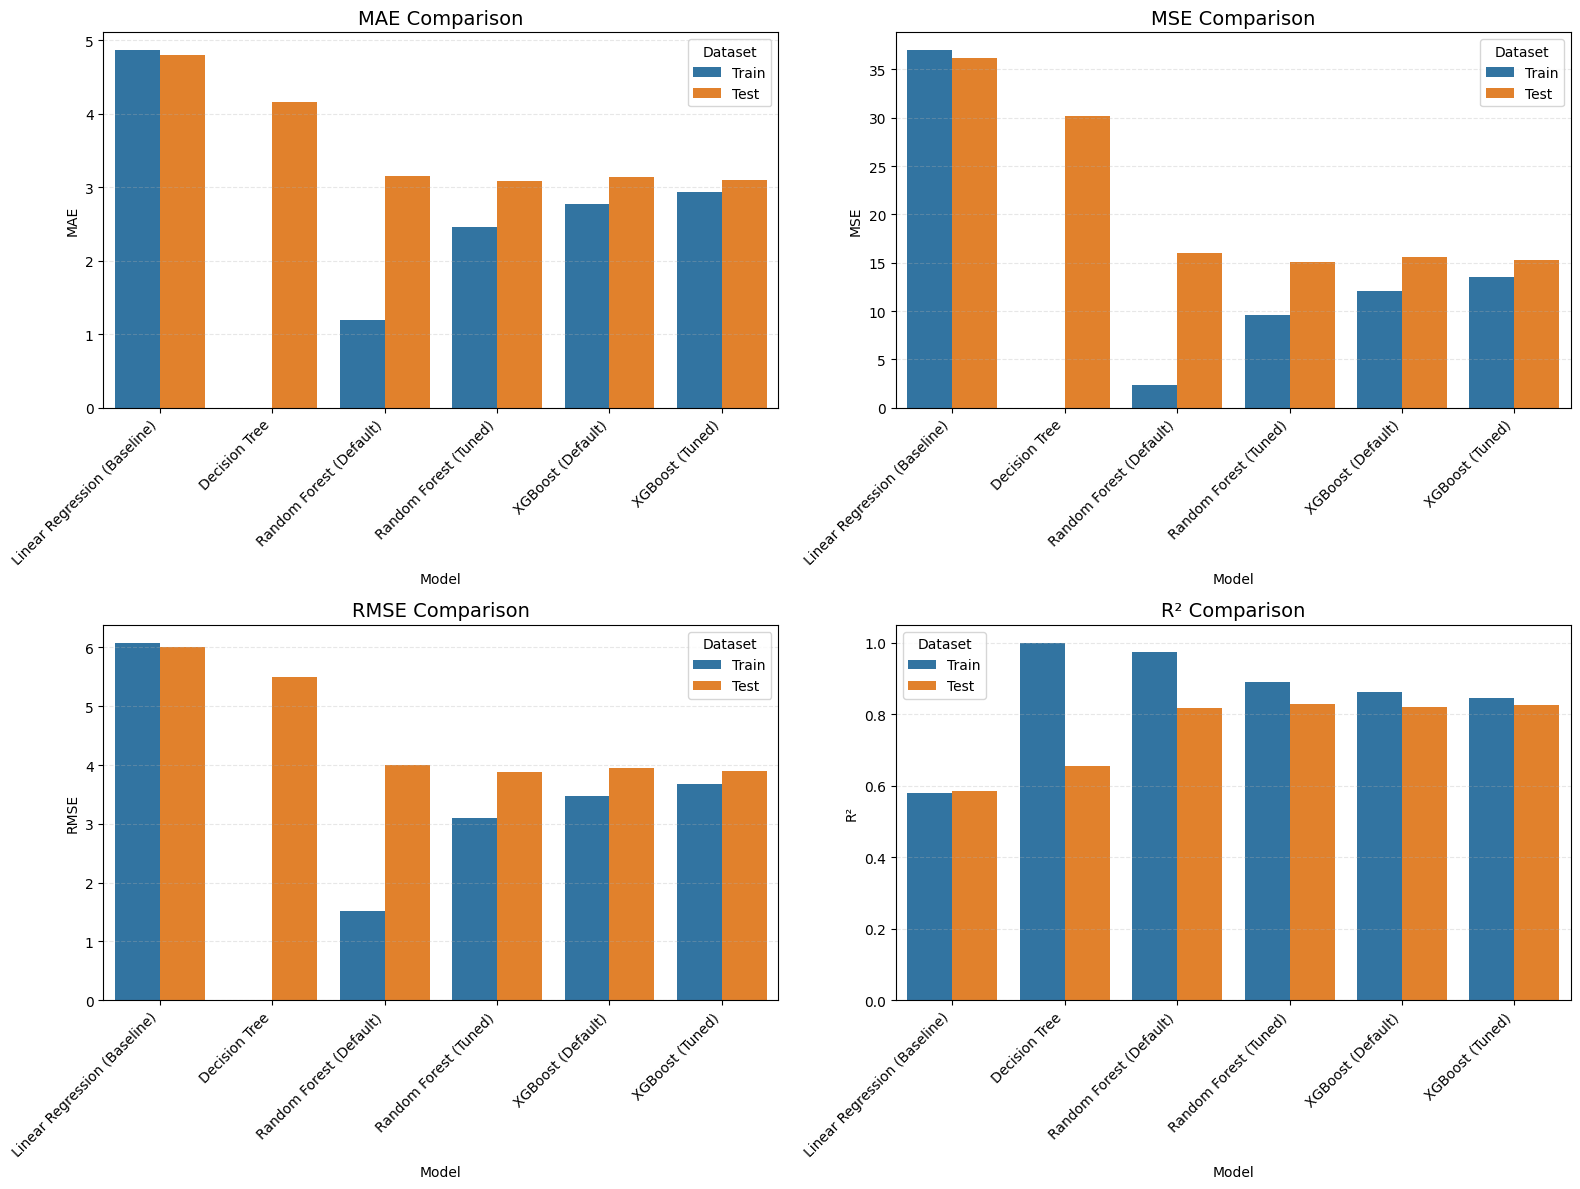

In [591]:

plt.figure(figsize=(16, 12))

metrics = ["MAE", "MSE", "RMSE", "R²"]

for i, metric in enumerate(metrics):
    plt.subplot(2, 2, i + 1)

    sns.barplot(
        data=comparison_df,
        x="Model",
        y=metric,
        hue="Dataset"
    )

    plt.title(f"{metric} Comparison", fontsize=14)
    plt.xlabel("Model")
    plt.ylabel(metric)
    plt.xticks(rotation=45, ha="right")
    plt.legend(title="Dataset")
    plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


In [594]:
import joblib


joblib.dump(rf_best, "rf_best.pkl")


model = joblib.load("rf_best.pkl")
scaler = joblib.load("standard_scaler.pkl")

In [596]:
X_test[0:3]

,Delivery_person_Age,Delivery_person_Ratings,distance_km,order_hour,Road_traffic_density,Vehicle_condition,multiple_deliveries,Type_of_order_Drinks,Type_of_order_Meal,Type_of_order_Snack,...,Type_of_vehicle_motorcycle,Type_of_vehicle_scooter,Festival_Yes,City_Semi-Urban,City_Urban,Weather_conditions_Fog,Weather_conditions_Sandstorms,Weather_conditions_Stormy,Weather_conditions_Sunny,Weather_conditions_Windy
25875,34.0,5.0,13.762197,23.0,0,2,0.0,0,0,0,...,0,1,0,0,0,0,0,1,0,0
12301,34.0,4.6,20.206582,20.0,3,0,1.0,0,0,0,...,1,0,1,0,0,0,0,0,0,0
2635,27.0,4.9,7.683783,19.0,0,2,1.0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
